# 06 — Análise Exploratória do ADHD-200

**Objetivo:** descrever a amostra validada no Notebook 05, examinar a distribuição dos grupos por site, idade e gênero, e visualizar padrões gerais de conectividade funcional.

**Importante**
- Este notebook é descritivo: os gráficos não demonstram que uma conexão causa ou diagnostica TDAH.
- A amostra esperada é de **709 participantes** (453 controles e 256 participantes com TDAH), definida nos notebooks anteriores.



In [1]:
# 1. Configuração e verificação dos arquivos
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Localiza config.py mesmo se o notebook for aberto a partir da pasta notebooks/
candidatos_raiz = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
raiz_projeto = next((p for p in candidatos_raiz if (p / "config.py").is_file()), None)

if raiz_projeto is None:
    raise FileNotFoundError(
        "Não encontrei config.py. Abra o notebook dentro da pasta TCC_TDAH "
        "ou de sua subpasta notebooks/."
    )

if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import config

# Usa o nome atual do projeto; cria a pasta de figuras se necessário.
pasta_figuras = Path(config.FIGURES)
pasta_figuras.mkdir(parents=True, exist_ok=True)

arquivo_participantes = Path(config.ARQ_PARTICIPANTES)
pasta_conectividade = Path(config.CONNECTIVITY)

dados_disponiveis = arquivo_participantes.is_file() and pasta_conectividade.is_dir()
print(f"Raiz do projeto: {raiz_projeto}")
print(f"Arquivo de participantes: {arquivo_participantes} | existe: {arquivo_participantes.is_file()}")
print(f"Pasta de conectividade: {pasta_conectividade} | existe: {pasta_conectividade.is_dir()}")

if not dados_disponiveis:
    print(
        "\nOs dados ainda não estão disponíveis neste computador. "
        "As células de análise vão informar que foram ignoradas. "
        "Execute novamente quando participants.csv e data/connectivity/ estiverem presentes."
    )


Raiz do projeto: C:\Users\Maria Eduarda\Downloads\TCC_TDAH
Arquivo de participantes: C:\Users\Maria Eduarda\Downloads\TCC_TDAH\data\processed\participants.csv | existe: True
Pasta de conectividade: C:\Users\Maria Eduarda\Downloads\TCC_TDAH\data\connectivity | existe: True


In [2]:
# 2. Carregamento e padronização das colunas
if dados_disponiveis:
    df_original = pd.read_csv(arquivo_participantes, dtype=str)

    # Aceita os nomes usados nas versões anteriores e os nomes definidos em config.py.
    aliases = {
        "participant_id": ["participant_id", "ID_padronizado", "id_participante", "ID"],
        "target": ["target", "classe", "class", "label"],
        "site": ["site", "Site", "SITE"],
        "Age": ["Age", "age", "idade", "IDADE"],
        "Gender": ["Gender", "gender", "sexo", "Sex"],
    }

    renomear = {}
    for nome_padrao, opcoes in aliases.items():
        encontrado = next((col for col in opcoes if col in df_original.columns), None)
        if encontrado is not None and encontrado != nome_padrao:
            renomear[encontrado] = nome_padrao

    df = df_original.rename(columns=renomear).copy()

    obrigatorias = ["participant_id", "target", "site"]
    ausentes = [col for col in obrigatorias if col not in df.columns]
    if ausentes:
        raise ValueError(
            f"Faltam colunas obrigatórias em {arquivo_participantes}: {ausentes}. "
            f"Colunas encontradas: {df_original.columns.tolist()}"
        )

    df["participant_id"] = df["participant_id"].astype(str).str.strip()
    df["target"] = pd.to_numeric(df["target"], errors="coerce")
    df["site"] = df["site"].astype("string").str.strip()

    # Idade e gênero são opcionais; quando presentes, convertemos apenas o necessário.
    if "Age" in df.columns:
        df["Age"] = pd.to_numeric(df["Age"], errors="coerce")
    if "Gender" in df.columns:
        df["Gender"] = df["Gender"].astype("string").str.strip()

    # Mantém somente rótulos binários válidos; não transforma valores desconhecidos em TDAH.
    df = df[df["target"].isin([0, 1])].copy()
    df["target"] = df["target"].astype(int)
    df["classe"] = df["target"].map({0: "Controle", 1: "TDAH"})

    if df["participant_id"].duplicated().any():
        ids_duplicados = df.loc[df["participant_id"].duplicated(), "participant_id"].tolist()[:10]
        raise ValueError(f"Há IDs duplicados em participants.csv. Exemplos: {ids_duplicados}")

    # Confirma que há uma matriz FC para cada participante e preserva a ordem da tabela.
    caminhos_fc = [pasta_conectividade / f"FC_{pid}.npy" for pid in df["participant_id"]]
    faltantes_fc = [pid for pid, caminho in zip(df["participant_id"], caminhos_fc) if not caminho.is_file()]
    if faltantes_fc:
        raise FileNotFoundError(
            f"Faltam {len(faltantes_fc)} matrizes FC. Exemplos de IDs: {faltantes_fc[:10]}. "
            "Confira se data/connectivity/ contém os arquivos FC_<ID>.npy."
        )

    fc = np.stack([np.load(caminho, allow_pickle=False) for caminho in caminhos_fc]).astype(np.float32)

    n_rois = int(config.N_ROIS)
    forma_esperada = (len(df), n_rois, n_rois)
    if fc.shape != forma_esperada:
        raise ValueError(f"Formato das matrizes FC {fc.shape}; esperado {forma_esperada}.")

    y = df["target"].to_numpy(dtype=int)
    print(f"Participantes carregados: {len(df)}")
    print(f"Formato das matrizes FC: {fc.shape}")
    print("Distribuição das classes:")
    display(df["classe"].value_counts().rename_axis("Grupo").to_frame("N"))
    print("Colunas disponíveis após padronização:", df.columns.tolist())
else:
    print("Célula ignorada: dados não encontrados neste computador.")


Participantes carregados: 709
Formato das matrizes FC: (709, 190, 190)
Distribuição das classes:


,N
Grupo,
Controle,453
TDAH,256


Colunas disponíveis após padronização: ['site', 'subject_id', 'arquivo', 'caminho', 'participant_id', 'ScanDir ID', 'Site', 'Gender', 'Age', 'Handedness', 'DX', 'Secondary Dx', 'ADHD Measure', 'ADHD Index', 'Inattentive', 'Hyper/Impulsive', 'IQ Measure', 'Verbal IQ', 'Performance IQ', 'Full2 IQ', 'Full4 IQ', 'Med Status', 'QC_Athena', 'QC_NIAK', 'target', 'classe']


classe,Controle,TDAH
site,,
KKI,58,22
NYU,87,103
NeuroIMAGE,21,20
OHSU,38,34
Peking_1,59,23
Peking_2,32,35
Peking_3,23,19
Pittsburgh,88,0
WashU,47,0


Qui-quadrado: χ²=123.946; gl=8; p=5.072e-23
V de Cramér: 0.418
Células com frequência esperada < 5: 0.0%


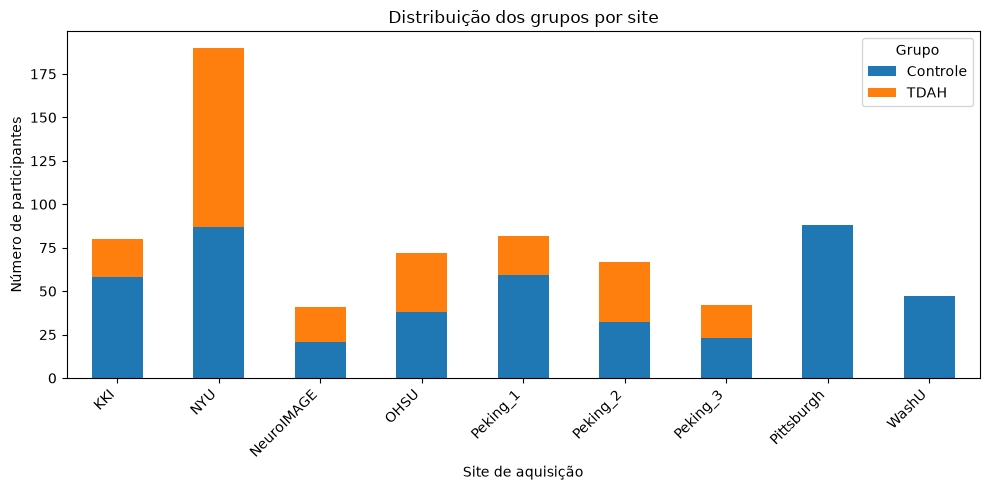

In [3]:
# 3. Distribuição dos grupos por site
if dados_disponiveis:
    tabela_site = pd.crosstab(df["site"], df["classe"], dropna=False)
    display(tabela_site)

    # Qui-quadrado é uma análise de associação, não de causalidade.
    if tabela_site.shape[0] >= 2 and tabela_site.shape[1] >= 2:
        chi2, p_valor, gl, esperadas = stats.chi2_contingency(tabela_site)
        n_total = tabela_site.to_numpy().sum()
        menor_dimensao = min(tabela_site.shape[0] - 1, tabela_site.shape[1] - 1)
        v_cramer = np.sqrt(chi2 / (n_total * menor_dimensao)) if menor_dimensao > 0 and n_total > 0 else np.nan
        percentual_esperadas_baixas = 100 * np.mean(esperadas < 5)

        print(f"Qui-quadrado: χ²={chi2:.3f}; gl={gl}; p={p_valor:.4g}")
        print(f"V de Cramér: {v_cramer:.3f}")
        print(f"Células com frequência esperada < 5: {percentual_esperadas_baixas:.1f}%")
        if percentual_esperadas_baixas > 20:
            print("Atenção: muitas frequências esperadas são pequenas; interprete o teste qui-quadrado com cautela.")
    else:
        print("Não foi possível calcular o qui-quadrado: a tabela não tem dimensões suficientes.")

    ax = tabela_site.plot(kind="bar", stacked=True, figsize=(10, 5))
    ax.set_title("Distribuição dos grupos por site")
    ax.set_xlabel("Site de aquisição")
    ax.set_ylabel("Número de participantes")
    ax.legend(title="Grupo")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(pasta_figuras / "06_classe_por_site.png", dpi=160, bbox_inches="tight")
    plt.show()
else:
    print("Célula ignorada: dados não encontrados.")


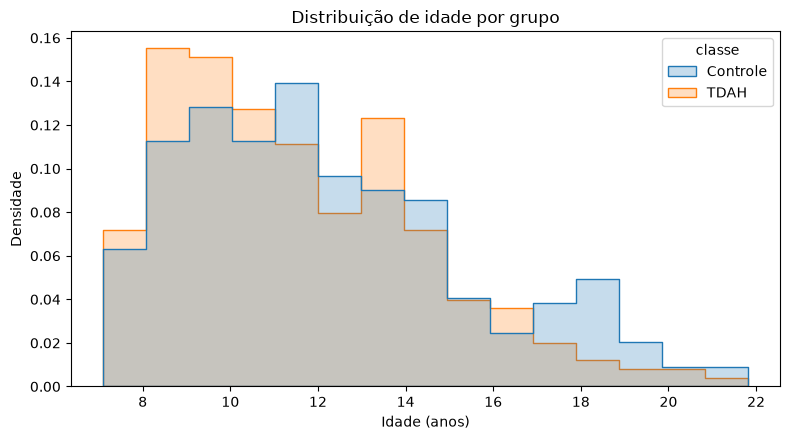

Idade — controle: n=453, mediana=11.69
Idade — TDAH: n=256, mediana=11.04
Mann–Whitney U=64616.5; p=0.01135


classe,Controle,TDAH
Gender,,
0.0,216,54
1.0,237,201
Ausente,0,1


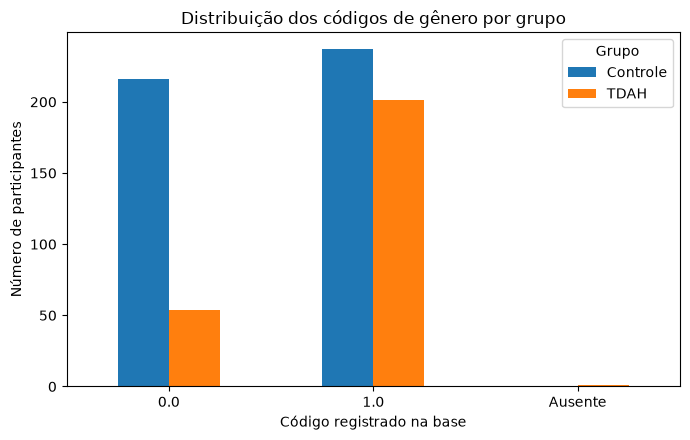

In [4]:
# 4. Distribuição por idade e gênero (se essas colunas estiverem disponíveis)
if dados_disponiveis:
    tem_idade = "Age" in df.columns and df["Age"].notna().any()
    tem_genero = "Gender" in df.columns and df["Gender"].notna().any()

    if tem_idade:
        plt.figure(figsize=(8, 4.5))
        sns.histplot(
            data=df.dropna(subset=["Age"]),
            x="Age",
            hue="classe",
            element="step",
            stat="density",
            common_norm=False,
            kde=False
        )
        plt.title("Distribuição de idade por grupo")
        plt.xlabel("Idade (anos)")
        plt.ylabel("Densidade")
        plt.tight_layout()
        plt.savefig(pasta_figuras / "06_distribuicao_idade.png", dpi=160, bbox_inches="tight")
        plt.show()

        idade_controle = df.loc[df["target"] == 0, "Age"].dropna()
        idade_tdah = df.loc[df["target"] == 1, "Age"].dropna()
        if len(idade_controle) and len(idade_tdah):
            teste_idade = stats.mannwhitneyu(idade_controle, idade_tdah, alternative="two-sided")
            print(f"Idade — controle: n={len(idade_controle)}, mediana={idade_controle.median():.2f}")
            print(f"Idade — TDAH: n={len(idade_tdah)}, mediana={idade_tdah.median():.2f}")
            print(f"Mann–Whitney U={teste_idade.statistic:.1f}; p={teste_idade.pvalue:.4g}")
    else:
        print("Coluna de idade não encontrada ou sem valores válidos; análise de idade ignorada.")

    if tem_genero:
        tabela_genero = pd.crosstab(df["Gender"].fillna("Ausente"), df["classe"])
        display(tabela_genero)
        ax = tabela_genero.plot(kind="bar", figsize=(7, 4.5))
        ax.set_title("Distribuição dos códigos de gênero por grupo")
        ax.set_xlabel("Código registrado na base")
        ax.set_ylabel("Número de participantes")
        ax.legend(title="Grupo")
        plt.xticks(rotation=0)
        plt.tight_layout()
        plt.savefig(pasta_figuras / "06_distribuicao_genero.png", dpi=160, bbox_inches="tight")
        plt.show()
    else:
        print("Coluna de gênero não encontrada ou sem valores válidos; análise de gênero ignorada.")
else:
    print("Célula ignorada: dados não encontrados.")


Resumo da conectividade média assinada por grupo:


,count,mean,std,median
classe,,,,
Controle,453,0.007013,0.005485,0.005750
TDAH,256,0.007953,0.005846,0.006809


Resumo da conectividade média absoluta por grupo:


,count,mean,std,median
classe,,,,
Controle,453,0.197368,0.024906,0.193286
TDAH,256,0.198055,0.034039,0.192846


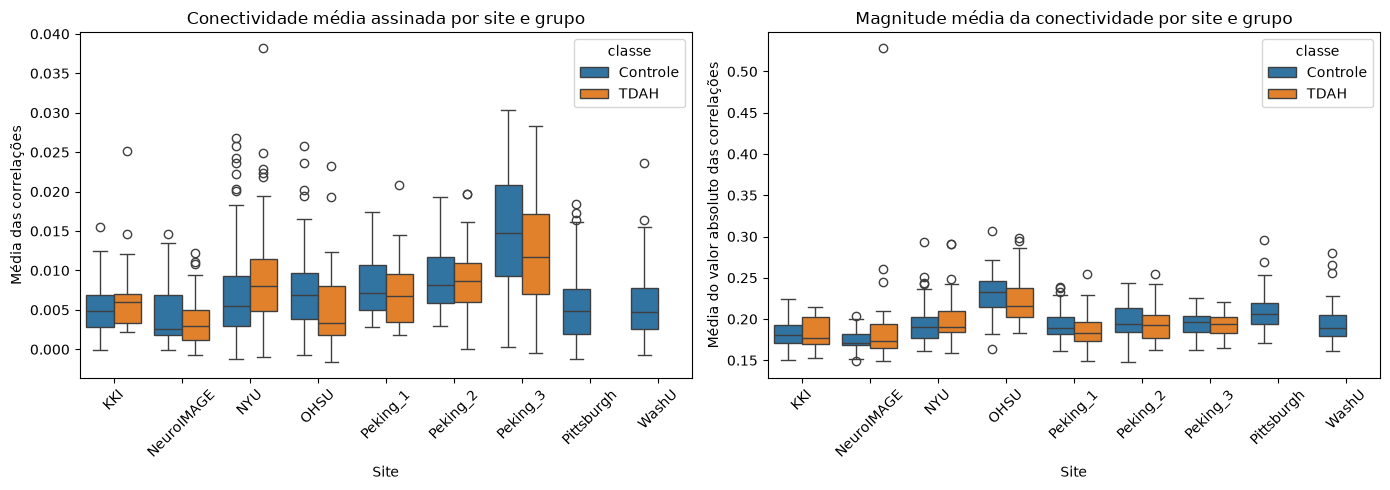

Nota: essas médias resumem muitas conexões em um único número e não substituem a análise dos padrões completos.


In [5]:
# 5. Conectividade média por participante e por site
if dados_disponiveis:
    indices_superiores = np.triu_indices(int(config.N_ROIS), k=1)
    conexoes = fc[:, indices_superiores[0], indices_superiores[1]]

    # Média assinada e média absoluta são medidas descritivas diferentes.
    df["fc_media_assinada"] = np.nanmean(conexoes, axis=1)
    df["fc_media_absoluta"] = np.nanmean(np.abs(conexoes), axis=1)

    print("Resumo da conectividade média assinada por grupo:")
    display(df.groupby("classe")["fc_media_assinada"].agg(["count", "mean", "std", "median"]))
    print("Resumo da conectividade média absoluta por grupo:")
    display(df.groupby("classe")["fc_media_absoluta"].agg(["count", "mean", "std", "median"]))

    fig, ax = plt.subplots(1, 2, figsize=(14, 5))
    sns.boxplot(data=df, x="site", y="fc_media_assinada", hue="classe", ax=ax[0])
    ax[0].set_title("Conectividade média assinada por site e grupo")
    ax[0].set_xlabel("Site")
    ax[0].set_ylabel("Média das correlações")
    ax[0].tick_params(axis="x", rotation=45)

    sns.boxplot(data=df, x="site", y="fc_media_absoluta", hue="classe", ax=ax[1])
    ax[1].set_title("Magnitude média da conectividade por site e grupo")
    ax[1].set_xlabel("Site")
    ax[1].set_ylabel("Média do valor absoluto das correlações")
    ax[1].tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.savefig(pasta_figuras / "06_fc_media_site.png", dpi=160, bbox_inches="tight")
    plt.show()
    print("Nota: essas médias resumem muitas conexões em um único número e não substituem a análise dos padrões completos.")
else:
    print("Célula ignorada: dados não encontrados.")


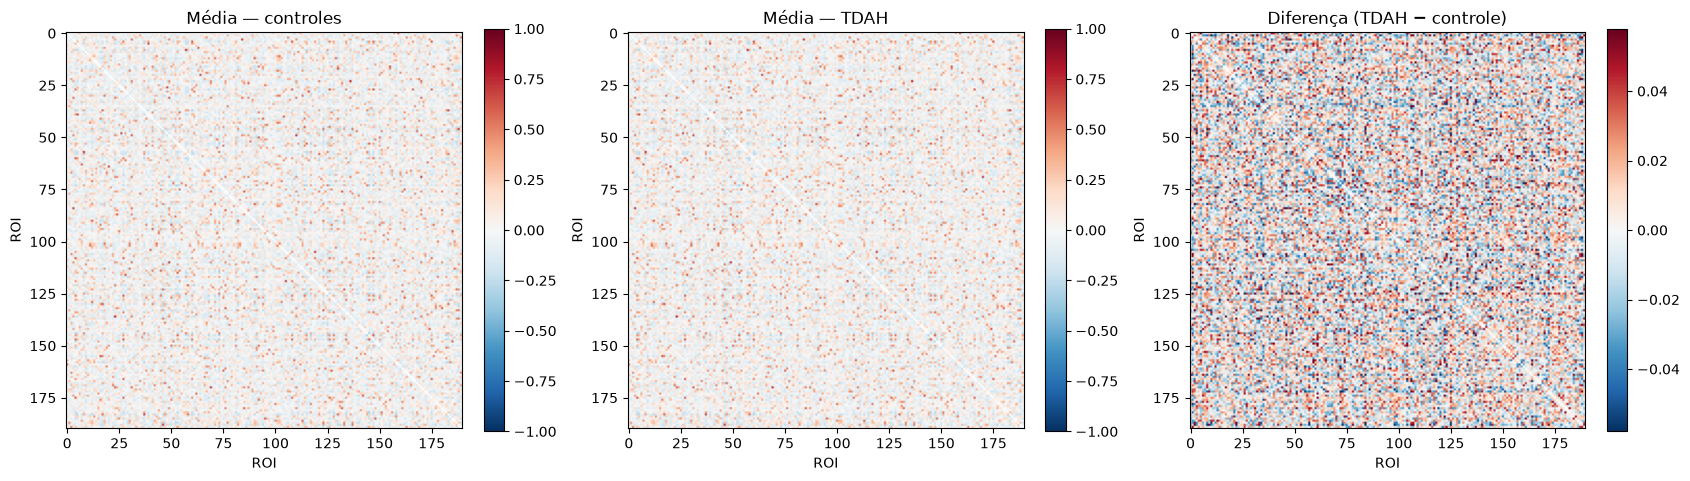

Interpretação: as matrizes mostram médias descritivas da amostra. A diferença visual, por si só, não indica significância estatística nem valor diagnóstico.


In [6]:
# 6. Matrizes médias de conectividade por grupo
if dados_disponiveis:
    matriz_controle = fc[y == 0].mean(axis=0)
    matriz_tdah = fc[y == 1].mean(axis=0)
    matriz_diferenca = matriz_tdah - matriz_controle

    # A diagonal contém autocorrelações iguais a 1; ocultá-la melhora a leitura das conexões entre ROIs.
    mascara_diagonal = np.eye(int(config.N_ROIS), dtype=bool)
    matrizes_plot = [matriz_controle.copy(), matriz_tdah.copy(), matriz_diferenca.copy()]
    for matriz in matrizes_plot:
        matriz[mascara_diagonal] = np.nan

    limite_diferenca = np.nanpercentile(np.abs(matriz_diferenca[~mascara_diagonal]), 99)
    if not np.isfinite(limite_diferenca) or limite_diferenca == 0:
        limite_diferenca = 0.01

    fig, ax = plt.subplots(1, 3, figsize=(17, 5))
    im0 = ax[0].imshow(matrizes_plot[0], cmap="RdBu_r", vmin=-1, vmax=1)
    ax[0].set_title("Média — controles")
    fig.colorbar(im0, ax=ax[0], fraction=0.046)

    im1 = ax[1].imshow(matrizes_plot[1], cmap="RdBu_r", vmin=-1, vmax=1)
    ax[1].set_title("Média — TDAH")
    fig.colorbar(im1, ax=ax[1], fraction=0.046)

    im2 = ax[2].imshow(matrizes_plot[2], cmap="RdBu_r", vmin=-limite_diferenca, vmax=limite_diferenca)
    ax[2].set_title("Diferença (TDAH − controle)")
    fig.colorbar(im2, ax=ax[2], fraction=0.046)

    for eixo in ax:
        eixo.set_xlabel("ROI")
        eixo.set_ylabel("ROI")

    plt.tight_layout()
    plt.savefig(pasta_figuras / "06_fc_media_classes.png", dpi=160, bbox_inches="tight")
    plt.show()

    print(
        "Interpretação: as matrizes mostram médias descritivas da amostra. "
        "A diferença visual, por si só, não indica significância estatística nem valor diagnóstico."
    )
else:
    print("Célula ignorada: dados não encontrados.")
